In [1]:
%pip install pandas matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [51]:
import pandas as pd

coo = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/COO.csv")
on = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/ON.csv")
tfc = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/TFC.csv")
trow = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/TROW.csv")

coo["Ticker"] = "COO"
on["Ticker"] = "ON"
tfc["Ticker"] = "TFC"
trow["Ticker"] = "TROW"

df = pd.concat([coo, on, tfc, trow])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,107.004,107.371,104.577,105.365,1390000,0.0,0.0,COO
2022-01-03,68.530,70.330,67.770,70.170,7049900,0.0,0.0,ON
2022-01-03,158.217,159.525,155.314,156.084,933500,0.0,0.0,TROW
2022-01-03,46.497,47.390,46.473,47.335,5677600,0.0,0.0,TFC
2022-01-04,154.062,157.856,154.038,156.517,1082400,0.0,0.0,TROW


In [22]:
df.groupby("Ticker")["Close"].agg(["mean","std","min","max"])

,mean,std,min,max
Ticker,,,,
COO,87.226778,11.226191,62.157,111.230
ON,66.804291,14.592650,31.950,108.090
TFC,36.562435,6.656859,21.600,52.829
TROW,98.235802,10.232890,74.331,156.517


In [24]:
flat_days = df[df["High"] == df["Low"]]
print(flat_days)

Empty DataFrame
Columns: [Open, High, Low, Close, Volume, Dividends, Stock Splits, Ticker]
Index: []


In [25]:
g = df.groupby("Ticker")
pd.DataFrame({
    "highest_high": g["High"].max(),
    "date_of_high": g["High"].idxmax(),
    "lowest_low": g["Low"].min(),
    "date_of_low": g["Low"].idxmin(),
})

,highest_high,date_of_high,lowest_low,date_of_low
Ticker,,,,
COO,112.380,2024-09-16,61.045,2022-10-13
ON,111.350,2023-07-31,31.040,2025-04-08
TFC,54.036,2022-01-18,21.064,2023-05-04
TROW,159.525,2022-01-03,72.090,2025-04-07


In [60]:
log_return = np.diff(np.log(Ticker), axis=0)
stats = log_returns.agg(['min', 'max', 'mean', 'std', 'skew']).T
print(stats)

df["ret"] = df.groupby("Ticker")["Close"].pct_change()
df.groupby("Ticker")["ret"].agg(["mean", "std", "min", "max"])

NameError: name 'log_returns' is not defined

In [41]:
g = df.groupby("Ticker")
pd.DataFrame({
    "2nd_date_of_high": g["High"].idxmax(2),
    "2nd_date_of_low": g["Low"].idxmin(2),
})

,2nd_date_of_high,2nd_date_of_low
Ticker,,
COO,2024-09-16,2022-10-13
ON,2023-07-31,2025-04-08
TFC,2022-01-18,2023-05-04
TROW,2022-01-03,2025-04-07


In [44]:
#df.resample("W").mean()
weekly_volume = df.groupby("Ticker")["Volume"].resample('W').sum()
print(weekly_volume)

Ticker  Date      
COO     2022-01-09     5351600
        2022-01-16    10742400
        2022-01-23     6381600
        2022-01-30     7704400
        2022-02-06     5475600
                        ...   
TROW    2025-12-07     8593100
        2025-12-14    10284700
        2025-12-21    12247500
        2025-12-28     5015400
        2026-01-04     2848800
Name: Volume, Length: 836, dtype: int64


In [61]:
lowest_company = log_return.sum().idxmin()
lowest_return = log_return.sum().min()

NameError: name 'log_return' is not defined

In [46]:
#Create a new column volume_class with categories (e.g., “Low”, “Medium”,“High”) based on volume tertiles within the given company.

In [48]:
#(A) Plot the log-returns of the companies (ideally in the same plot). (B) Plot the distribution of log-returns (ideally in the same plot).

In [75]:
comp_no = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/companies_no_subindustry.csv")
comp_sub = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/companies_subindustry.csv")

comp_no["companies"] = "comp no"
comp_sub["companies"] = "comb sub"

df = pd.concat([comp_no, comp_sub])

df.groupby("companies")["Close"].agg(["mean","std","min","max"])


KeyError: 'Column not found: High'

In [58]:
comp_no = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/companies_no_subindustry.csv")
print(comp_no.isna().sum())
comp_sub = pd.read_csv("/Users/eleabeaudouxcreissel/Midterm Exam/companies_subindustry.csv")
print(comp_sub.isna().sum())

Symbol          0
Security        0
GICS_Sector     0
hq              0
included       45
Founded         0
dtype: int64
Symbol         0
subindustry    0
dtype: int64


In [76]:
comp_no["included"] = pd.to_datetime(comp_no["included"], dayfirst=True, errors="coerce")
comp_no = comp_no.dropna()
len(comp_no)

oldest = comp_no.loc[coins["listed"].idxmin()]
youngest = comp_no.loc[coins["listed"].idxmax()]

print("Oldest:  ", oldest["listed"].date())
print("Youngest:", youngest["listed"].date())

comp_no.groupby("companies")["Founded"].median()

NameError: name 'coins' is not defined

In [77]:
g = df.groupby("companies")
pd.DataFrame({
....})

plot = df.plot.pie(y="sectors", figsize=(10, 10))
print(plot)

KeyError: 'Column not found: High'

ValueError: not enough values to unpack (expected 2, got 1)

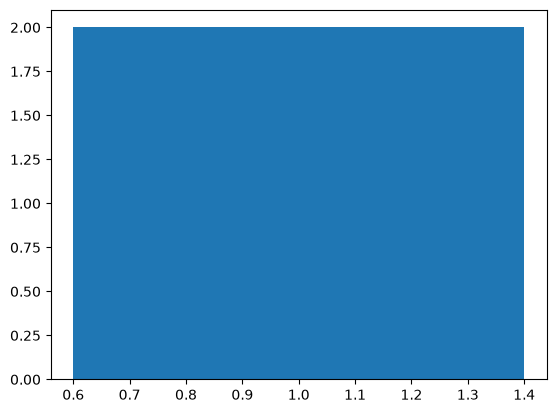

In [78]:
fig, axes = plt.bar(1,2)

axes[0].bar(normal_sample, bins=30)
axes[0].set_title("...")

axes[1].bar(uniform_sample, bins=30)
axes[1].set_title("...")
plt.show()